# **Exp 10(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping & Targeted Median Imputation**

1. Separate features and target, excluding customer ID and raw date columns. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Select four high-missing numerical features for targeted median imputation:
   - mid_peak_fix_cv
   - peak_fix_cv
   - mid_peak_var_cv
   - peak_var_cv
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits from training data and apply them within each CV fold.
7. Apply separate median imputation pipelines for the four high-missing features and the remaining numerical features.
8. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
9. Handle class imbalance using class_weight='balanced' in Random Forest.
10. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
11. Extract and display the median values used for imputing the four selected features.
12. Generate validation probabilities and perform fine-grained threshold analysis (0.05–0.95, with 0.01 intervals).
13. Select the threshold with the highest validation F1 Score.
14. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
15. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
16. Analyse and visualize the top 20 feature importances.
17. Display the imputed columns, best CV PR-AUC, selected threshold, test PR-AUC, and test F1 Score.

this experiment incorporates changes to the original Exp 2 model based on median imputation    
Exp 11(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp11

### 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

### 1. FEATURES AND TARGET

In [3]:
date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']
drop_cols = ['id', 'churn'] + [col for col in date_cols if col in df.columns]

X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("Dataset Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Dataset Shape: (14606, 104)
Total Missing Values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


### 2. TRAIN / VALIDATION / TEST SPLITS

In [4]:
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=42, stratify=y_train_full
)

print("\nSplit Sizes:")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Split Sizes:
Model Training: (9347, 104)
Validation: (2337, 104)
Test: (2922, 104)


### 3. FEATURE TYPES

In [5]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))


Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns: 101


### 4. FOUR HIGH-MISSING NUMERIC FEATURES

In [6]:
high_missing_features = [
    'mid_peak_fix_cv',
    'peak_fix_cv',
    'mid_peak_var_cv',
    'peak_var_cv'
]
high_missing_features = [
    col for col in high_missing_features
    if col in X_model_train.columns
]

non_numeric_targets = [
    col for col in high_missing_features
    if col not in numerical_cols
]
if non_numeric_targets:
    raise ValueError(
        f"Requested median-imputation features are not numeric: {non_numeric_targets}"
    )

other_numerical_cols = [
    col for col in numerical_cols
    if col not in high_missing_features
]

print("\nFour High-Missing Features:")
print(high_missing_features)
print("\nMissing Counts Before Imputation:")
print(X_model_train[high_missing_features].isna().sum())


Four High-Missing Features:
['mid_peak_fix_cv', 'peak_fix_cv', 'mid_peak_var_cv', 'peak_var_cv']

Missing Counts Before Imputation:
mid_peak_fix_cv    5730
peak_fix_cv        5730
mid_peak_var_cv    5722
peak_var_cv        4066
dtype: int64


### 5. OUTLIER CAPPING CONFIGURATION

In [7]:
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

### 6. OUTLIER CAPPING TRANSFORMER

In [8]:
# Limits are learned only from each training fold during CV.
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(self, two_sided_features=None, upper_only_features=None):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features

    def fit(self, X, y=None):
        self.cap_limits_ = {}
        for col in self.two_sided_features or []:
            self.cap_limits_[col] = {
                'lower': X[col].quantile(0.01),
                'upper': X[col].quantile(0.99)
            }
        for col in self.upper_only_features or []:
            self.cap_limits_[col] = {
                'lower': None,
                'upper': X[col].quantile(0.99)
            }
        return self

    def transform(self, X):
        X = X.copy()
        for col, limits in self.cap_limits_.items():
            if limits['lower'] is not None:
                X[col] = X[col].clip(lower=limits['lower'])
            if limits['upper'] is not None:
                X[col] = X[col].clip(upper=limits['upper'])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

### 7. OUTLIER CAPPING SUMMARY

In [9]:
# This summary is calculated from model-training data only.
summary_capper = OutlierCapper(
    two_sided_features=two_sided_features,
    upper_only_features=upper_only_features
)
summary_capper.fit(X_model_train)
X_model_train_capped_summary = summary_capper.transform(X_model_train)

cap_summary = []
for col, limits in summary_capper.cap_limits_.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped_summary[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped_summary[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)
print("\n==== OUTLIER CAPPING SUMMARY ====")
print(cap_summary_df.round(3).to_string(index=False))

print("\nMissing Values Before Imputation:")
print("Training:", int(X_model_train_capped_summary.isna().sum().sum()))
print("Validation:", int(summary_capper.transform(X_val).isna().sum().sum()))
print("Test:", int(summary_capper.transform(X_test).isna().sum().sum()))


==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -19883.990    449656.000  108516.213   -19883.990   108516.213
        forecast_cons_diff  -6207018.990 -3114341.674      1690.100     -26.706 -3114341.674      -26.706
price_consumption_exposure  -1563821.153  -100136.355    481476.438    7581.672  -100136.355     7581.672
     consumption_per_power         0.000        0.000    590028.897  186563.330          NaN   186563.330
                  cons_12m         0.000        0.000   6207104.000 3118110.000          NaN  3118110.000
           cons_last_month         0.000        0.000    771203.000  382647.000          NaN   382647.000
                   pow_max         3.300        3.300       320.000      77.108          NaN       77.108
        forecast_cons_year         0.000        0.000    175375.000   11417.160          NaN    11417.160
           

### 8. PREPROCESSING PIPELINES

In [10]:
# Separate median imputer for the four high-missing features.
high_missing_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

other_numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

transformers = [
    ('high_missing_median', high_missing_numeric_pipeline, high_missing_features),
    ('other_numeric_median', other_numeric_pipeline, other_numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols)
]

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder='drop',
    verbose_feature_names_out=False
)

### 9. RANDOM FOREST PIPELINE

In [11]:
rf_pipeline = Pipeline(steps=[
    ('outlier_capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

### 10. STRATIFIED CROSS VALIDATION

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### 11. HYPERPARAMETER SEARCH SPACE

In [13]:
param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [None, 10, 15, 20],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.3, 0.5],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

### 12. RANDOMIZED SEARCH CV

In [14]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

### 13. FIT RANDOMIZED SEARCH

In [15]:
# Raw training data is passed; capping and preprocessing happen inside CV.
random_search.fit(X_model_train, y_model_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__class_weight': ['balanced', 'balanced_subsample'], 'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [2, 5, ...], ...}"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


### 14. BEST HYPERPARAMETERS

In [16]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)
print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced_subsample'}

Best CV PR-AUC: 0.2706


### 15. BEST RANDOM FOREST MODEL

In [17]:
best_rf_pipeline = random_search.best_estimator_

### 16. RANDOMIZED SEARCH RESULTS

In [18]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score', ascending=False
)

result_cols = [
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__class_weight',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(search_results_df[result_cols].head(10).round(4).to_string(index=False))


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features param_model__class_weight  mean_train_score  mean_test_score  std_test_score
                       300                   None                               5                              5                       0.5        balanced_subsample            0.9997           0.2706          0.0226
                       700                     20                              10                              5                       0.5        balanced_subsample            0.9997           0.2698          0.0218
                       500                     20                              20                             15                       0.5        balanced_subsample            0.9372           0.2550          0.0206
                       500                     20                               5         

### 17. MEDIAN IMPUTATION VALUES

In [19]:
fitted_preprocessor = best_rf_pipeline.named_steps['preprocessing']

if high_missing_features:
    fitted_high_missing_imputer = (
        fitted_preprocessor
        .named_transformers_['high_missing_median']
        .named_steps['imputer']
    )
    median_values = pd.Series(
        fitted_high_missing_imputer.statistics_,
        index=high_missing_features,
        name='Training_Median_Used'
    )
    print("\n==== MEDIAN VALUES USED ====")
    print(median_values)


==== MEDIAN VALUES USED ====
mid_peak_fix_cv    0.001815
peak_fix_cv        0.001815
mid_peak_var_cv    0.016311
peak_var_cv        0.019743
Name: Training_Median_Used, dtype: float64


### 18. VALIDATION PROBABILITIES

In [20]:
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

### 19. PRECISION-RECALL CURVE

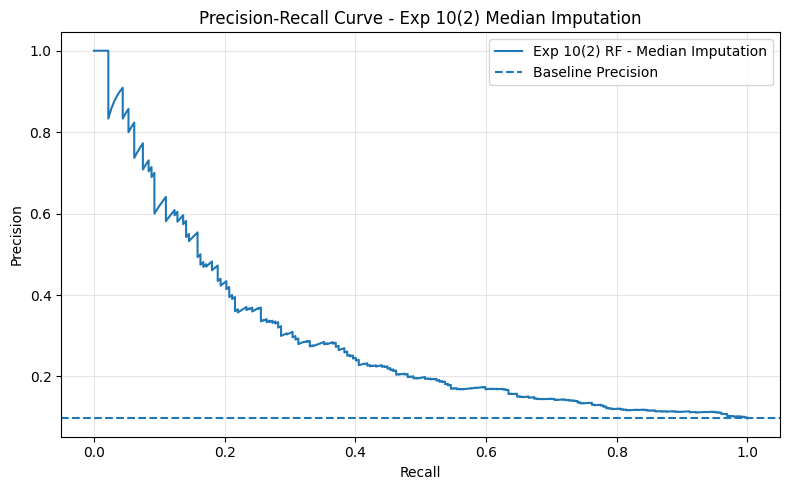

In [21]:
precision_curve, recall_curve, _ = precision_recall_curve(
    y_val, y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 10(2) RF - Median Imputation'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 10(2) Median Imputation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 20. VALIDATION THRESHOLD ANALYSIS


==== VALIDATION THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1019  0.9780    0.1846
      0.06     0.1049  0.9692    0.1893
      0.07     0.1078  0.9604    0.1938
      0.08     0.1115  0.9559    0.1996
      0.09     0.1124  0.9119    0.2002
      0.10     0.1143  0.8722    0.2020
      0.11     0.1180  0.8414    0.2069
      0.12     0.1198  0.7930    0.2081
      0.13     0.1268  0.7797    0.2181
      0.14     0.1352  0.7621    0.2296
      0.15     0.1402  0.7313    0.2353
      0.16     0.1444  0.6872    0.2387
      0.17     0.1502  0.6564    0.2445
      0.18     0.1589  0.6344    0.2542
      0.19     0.1691  0.6123    0.2650
      0.20     0.1687  0.5551    0.2587
      0.21     0.1811  0.5419    0.2715
      0.22     0.1928  0.5198    0.2813
      0.23     0.1982  0.4802    0.2806
      0.24     0.2134  0.4626    0.2921
      0.25     0.2249  0.4449    0.2988
      0.26     0.2306  0.4185    0.2973
      0.27     0.2401  0.4009    0.3003

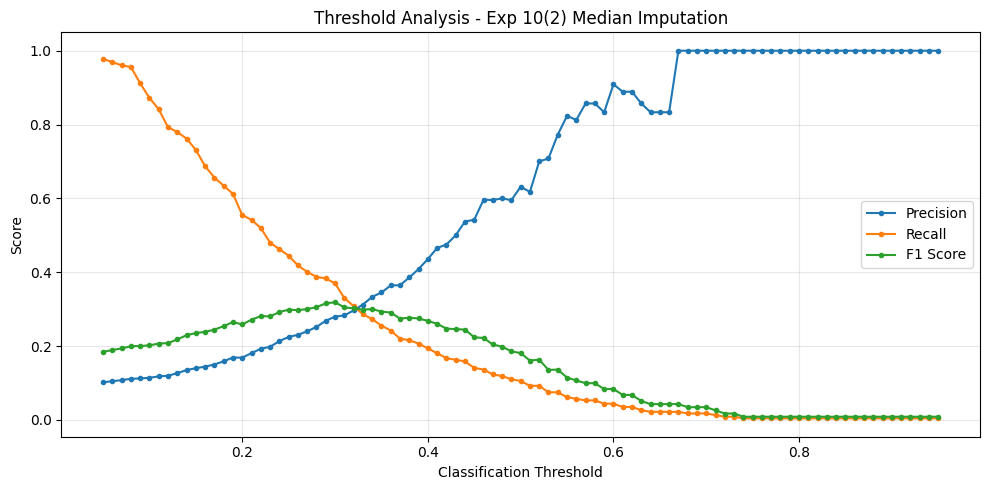

In [22]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

print("\n==== VALIDATION THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 10(2) Median Imputation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 21. SELECT BEST THRESHOLD

In [23]:
best_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_row['Threshold'])

print("\n==== SELECTED VALIDATION THRESHOLD ====")
print(f"Threshold: {best_threshold:.2f}")
print(best_row)


==== SELECTED VALIDATION THRESHOLD ====
Threshold: 0.30
Threshold    0.300000
Precision    0.280000
Recall       0.370044
F1 Score     0.318786
Name: 25, dtype: float64


### 22. PREDICTIONS

In [24]:
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

### 23. METRIC FUNCTION

In [25]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(y_model_train, y_pred_train, y_prob_train)
validation_metrics = calculate_metrics(y_val, y_pred_val, y_prob_val)
test_metrics = calculate_metrics(y_test, y_pred_test, y_prob_test)

### 24. PRINT METRICS

In [26]:
def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)


==== TRAIN METRICS ====
Accuracy    : 0.9759
Precision   : 0.8014
Recall      : 1.0000
F1 Score    : 0.8898
ROC-AUC     : 1.0000
PR-AUC      : 0.9996

==== VALIDATION METRICS ====
Accuracy    : 0.8464
Precision   : 0.2800
Recall      : 0.3700
F1 Score    : 0.3188
ROC-AUC     : 0.6943
PR-AUC      : 0.2922

==== TEST METRICS ====
Accuracy    : 0.8480
Precision   : 0.2849
Recall      : 0.3732
F1 Score    : 0.3232
ROC-AUC     : 0.6923
PR-AUC      : 0.3275


### 25. TEST CONFUSION MATRIX

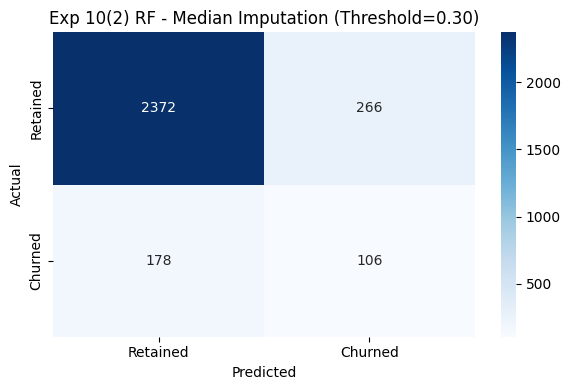

In [27]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Exp 10(2) RF - Median Imputation (Threshold={best_threshold:.2f})')
plt.tight_layout()
plt.show()

### 26. TEST CLASSIFICATION REPORT

In [28]:
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.90      0.91      2638
     Churned       0.28      0.37      0.32       284

    accuracy                           0.85      2922
   macro avg       0.61      0.64      0.62      2922
weighted avg       0.87      0.85      0.86      2922



### 27. FEATURE IMPORTANCE

In [29]:
rf_fitted = best_rf_pipeline.named_steps['model']
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    'Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))


==== TOP 20 FEATURE IMPORTANCES ====
                   Feature  Importance
        margin_net_pow_ele     0.06921
   forecast_meter_rent_12m     0.03948
      cons_last_month_diff     0.03162
       forecast_cons_ratio     0.02980
    margin_per_consumption     0.02822
              months_activ     0.02509
   price_power_interaction     0.02430
     consumption_per_power     0.02382
          margin_per_power     0.02264
price_consumption_exposure     0.02224
                   pow_max     0.02110
         months_modif_prod     0.02109
     cons_last_month_ratio     0.02068
        forecast_cons_diff     0.01896
        margin_per_product     0.01890
                  cons_12m     0.01757
   var_year_price_off_peak     0.01740
         forecast_cons_12m     0.01711
           cons_last_month     0.01591
            price_off_peak     0.01578


### 28. FEATURE IMPORTANCE VISUALIZATION

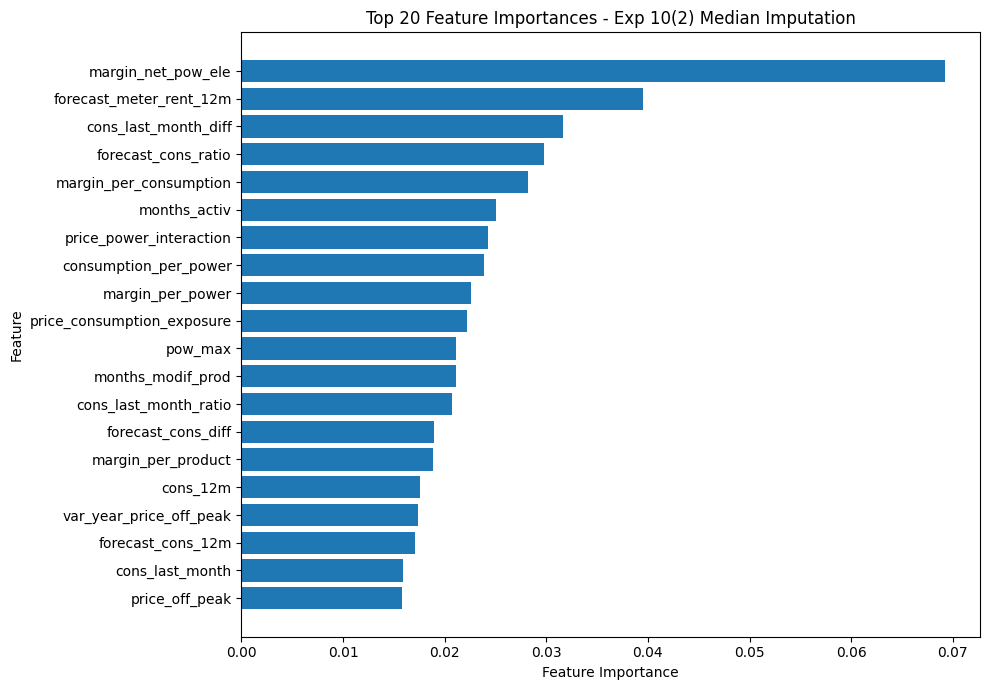

In [30]:
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 10(2) Median Imputation')
plt.tight_layout()
plt.show()

### 29. FINAL EXPERIMENT SUMMARY

In [31]:
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp10_2_RF_Median_Imputation']
)

print("\n" + "=" * 65)
print("EXP 10(2) - MEDIAN IMPUTATION COMPLETED")
print("=" * 65)
print("Imputed Columns:", high_missing_features)
print("Best CV PR-AUC:", round(random_search.best_score_, 4))
print("Selected Threshold:", round(best_threshold, 2))
print("Test PR-AUC:", round(test_metrics['PR-AUC'], 4))
print("Test F1:", round(test_metrics['F1 Score'], 4))


EXP 10(2) - MEDIAN IMPUTATION COMPLETED
Imputed Columns: ['mid_peak_fix_cv', 'peak_fix_cv', 'mid_peak_var_cv', 'peak_var_cv']
Best CV PR-AUC: 0.2706
Selected Threshold: 0.3
Test PR-AUC: 0.3275
Test F1: 0.3232


# **Observation:Exp 10(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping & Targeted Median Imputation**

- Applied outlier capping without removing entire records.
- Dataset size remained unchanged.
- Targeted median imputation addressed missing values in four high-missing numerical features.
- Training medians were used for imputation to avoid data leakage.
- This experiment evaluates whether combining outlier capping with targeted median imputation improves Random Forest performance.

2. Model Optimization

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Applied `class_weight='balanced_subsample'` to handle class imbalance.

**Best hyperparameters:**

- `n_estimators`: 300
- `min_samples_split`: 5
- `min_samples_leaf`: 5
- `max_features`: 0.5
- `max_depth`: None
- `class_weight`: balanced_subsample

\- Best CV PR-AUC: **27.06%**

**Observation:**

- The selected configuration uses 300 trees with minimum leaf samples of 5.
- Class weighting helps address the imbalance between churn and retained customers.
- CV PR-AUC of 27.06% is lower than Exp2 (30.55%) and Exp8(2) (27.35%).
- Training performance remains extremely high, indicating overfitting.

3. Model Performance – Test Data

- Accuracy: **84.80%**
- Precision: **28.49%**
- Recall: **37.32%**
- F1 Score: **32.32%**
- ROC-AUC: **69.23%**
- PR-AUC: **32.75%**

4. Threshold Analysis

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.30**, based on the highest F1 score in the threshold analysis.
- At threshold 0.30 (threshold validation):
  - Precision: 28.00%
  - Recall: 37.00%
  - F1 Score: 31.88%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a reasonable balance between precision and recall.
- At lower thresholds, the model identifies more churn customers but generates more false positives.
- At higher thresholds, precision improves but recall drops significantly.

5. Confusion Matrix (Threshold = 0.30)

- True Negatives: 2,372
- False Positives: 266
- False Negatives: 178
- True Positives: 106

**Observation:**

- Model correctly identifies 106 churn customers out of 284.
- It misses 178 actual churn customers.
- False positives are 266.
- The model identifies more churn customers than Exp9(4), which identified 78.
- However, it still misses a considerable number of actual churn customers.

6. Precision-Recall Curve

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.75% indicates reasonable churn identification capability.

**Observation:**

- The model performs better than random classification.
- Precision decreases as recall increases, showing the trade-off between identifying more churn customers and maintaining prediction accuracy.
- The model maintains higher precision than the baseline across most of the recall range.

7. Cross-Validation Results

- CV Training PR-AUC (mean): **99.97%**
- CV Validation PR-AUC (mean): **27.06%**
- CV Validation PR-AUC standard deviation: 2.26%

**Additional training metrics (full fit-training data):**

- Accuracy: 97.59%
- Precision: 80.14%
- Recall: 100%
- F1 Score: 88.98%
- ROC-AUC: 100%
- PR-AUC: 99.96%

**Observation:**

- Training PR-AUC is extremely high at 99.96%, whereas validation PR-AUC is only 27.06%.
- This significant gap indicates severe overfitting.
- Despite targeted median imputation and outlier capping, the model struggles to generalize effectively.
- The small CV validation PR-AUC standard deviation indicates relatively consistent validation performance across folds, but the overall predictive performance remains limited.

*Note: Fold-level CV classification metrics at the default 0.50 threshold were not included in the supplied results, so they are not reported here.*

8. Top 20 Important Features

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `months_activ`
- `price_power_interaction`
- `consumption_per_power`
- `margin_per_power`
- `price_consumption_exposure`
- `pow_max`
- `months_modif_prod`
- `cons_last_month_ratio`
- `forecast_cons_diff`
- `margin_per_product`
- `cons_12m`
- `var_year_price_off_peak`
- `forecast_cons_12m`
- `cons_last_month`
- `price_off_peak`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Engineered features such as `price_power_interaction` and `cons_last_month_ratio` also contribute to predictions.
- Feature importance patterns are consistent with earlier Random Forest experiments.

9. Model Comparison – All Experiments

| **Metric** | **Exp1-Baseline RF** | **Exp2-Regularized RF** | **Exp3-Strong Reg. RF** | **Exp4-XGBoost** | **Exp5-Strong Reg. XGB** | **Exp6-LightGBM** | **Exp7-SVM** | **Exp8(2)-RF** | **Exp9(2)-Capped RF** | **Exp9(4)-Capped XGB** | **Exp10(2)-Capped RF + Median** |
| ---------- | -------------------- | ----------------------- | ----------------------- | ---------------- | ------------------------ | ----------------- | ------------ | -------------- | --------------------- | ---------------------- | ------------------------------- |
| Accuracy   | 84.02%               | 87.34%                  | 84.94%                  | **89.39%**       | 86.69%                   | 88.02%            | 82.75%       | 82.07%         | 82.20%                | 89.05%                 | 84.80%                          |
| Precision  | 26.72%               | 34.86%                  | 29.26%                  | **43.09%**       | 31.83%                   | 36.48%            | 23.68%       | 25.71%         | 25.72%                | 40.62%                 | 28.49%                          |
| Recall     | 36.97%               | 34.86%                  | 38.73%                  | 28.52%           | 32.39%                   | 31.34%            | 34.86%       | **44.72%**     | 44.01%                | 27.46%                 | 37.32%                          |
| F1 Score   | 31.02%               | **34.86%**              | 33.33%                  | 34.32%           | 32.11%                   | 33.71%            | 28.21%       | 32.65%         | 32.47%                | 32.77%                 | 32.32%                          |
| ROC-AUC    | **70.76%**           | 70.48%                  | 69.45%                  | 69.24%           | 69.58%                   | 69.33%            | 66.45%       | 69.98%         | 69.10%                | 68.66%                 | 69.23%                          |
| PR-AUC     | 32.77%               | **35.75%**              | 31.71%                  | 32.15%           | 29.42%                   | 32.20%            | 20.13%       | 34.26%         | 32.43%                | 32.57%                 | 32.75%                          |
| CV PR-AUC  | 25.43%               | **30.55%**              | 26.15%                  | 28.42%           | 26.38%                   | 28.63%            | 20.85%       | 27.35%         | 26.98%                | 28.14%                 | 27.06%                          |

**Observation:**

- Exp10(2) achieves a test PR-AUC of 32.75%, slightly higher than Exp9(2) (32.43%) and Exp9(4) (32.57%).
- Its PR-AUC is lower than Exp2 (35.75%) and Exp8(2) (34.26%).
- Exp10(2) achieves precision of 28.49%, improving over Exp8(2) (25.71%) and Exp9(2) (25.72%).
- Its recall (37.32%) is lower than Exp8(2) (44.72%) and Exp9(2) (44.01%).
- Exp10(2) does not achieve the highest F1 Score; Exp2 remains the leader at 34.86%.
- Its CV PR-AUC (27.06%) is slightly lower than Exp8(2) (27.35%).
- Combining outlier capping with targeted median imputation has not produced a consistent improvement across evaluation metrics.
- Exp2 continues to provide the strongest overall balance between precision and recall.

10. Final Conclusion – Exp10(2) Random Forest

- Achieves a test PR-AUC of 32.75%.
- Achieves precision of 28.49% and recall of 37.32%.
- Correctly identifies 106 churn customers out of 284.
- Generates 266 false positives.
- Targeted median imputation addresses missing values in four high-missing numerical features.
- However, significant overfitting remains.
- Overall performance does not surpass Exp2 or Exp8(2).

**Best Model So Far
\: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

Exp10(2) provides a reasonable alternative, with improved precision compared with Exp8(2) and Exp9(2), but its overall F1 Score and PR-AUC remain lower than Exp2.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.30 threshold. Compare classification metrics cautiously.